# What Makes a Title Interesting — baseline

Kaggle: https://www.kaggle.com/competitions/what-makes-title-intresting

Regression: predict how interesting a content title is (1–6) from the title text and its source domain
(youtube / reddit / podcast / article). Metric: **MAE** (lower is better).

Important detail from the overview: the 120 **train** labels come from a *single* annotator each (integers, noisy),
while the 30 **test** labels are the *mean of 6 annotators* (smoother, pulled toward the middle).
So CV MAE against single-annotator labels is a pessimistic, noisy proxy; what we really want is a good estimate
of the *expected* rating, which squared-loss regression (+ shrinkage toward the mean) targets.

This notebook: load → EDA → repeated K-fold CV → baselines (constant, domain mean, hand-crafted features,
frozen sentence embeddings + ridge / SVR / kNN, a small MLP) → shrinkage → submission.

In [7]:
import random, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

SEED = 42
random.seed(SEED); np.random.seed(SEED)

DATA = Path("data")
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
sample = pd.read_csv(DATA / "sample_submission.csv")
print(train.shape, test.shape, sample.shape)
train.head()

(120, 4) (30, 3) (30, 2)


,title_id,title,domain,interest
0,T0001,"YFG Fatso - ""Bougie Hoes Pt 2 [Official Music ...",youtube,1
1,T0004,RuneScape - Official 4th MMO Teaser Trailer,youtube,6
2,T0005,We Found an ABANDONED AIRPLANE in Minecraft,youtube,1
3,T0009,We Automate Infinite Netherite - Sky Factory S...,youtube,4
4,T0011,How Hard Is Finding Bigfoot?,youtube,4


## EDA

interest
1    30
2    20
3    15
4    25
5    19
6    11
Name: count, dtype: int64
         mean   std  count
domain                    
article  3.43  1.57     30
podcast  2.90  1.75     30
reddit   3.50  1.57     30
youtube  2.70  1.78     30
test domains: {'youtube': 8, 'reddit': 8, 'article': 7, 'podcast': 7}


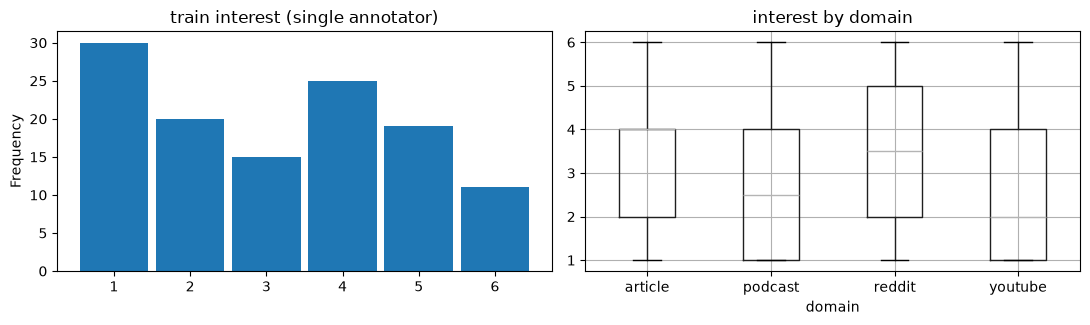

In [8]:
print(train["interest"].value_counts().sort_index())
print(train.groupby("domain")["interest"].agg(["mean", "std", "count"]).round(2))
print("test domains:", test["domain"].value_counts().to_dict())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
train["interest"].plot.hist(bins=np.arange(0.5, 7), ax=ax[0], rwidth=0.9, title="train interest (single annotator)")
train.boxplot(column="interest", by="domain", ax=ax[1]); ax[1].set_title("interest by domain"); plt.suptitle("")
plt.tight_layout(); plt.show()

In [9]:
for lab in (1, 6):
    print(f"========== interest {lab} ==========")
    for _, r in train[train.interest == lab].sample(5, random_state=SEED).iterrows():
        print(f"[{r.domain}] {r.title}")

========== interest 1 ==========
[podcast] Familia Positiva w/ Milly Tamarez
[article] Where to live stream Bills vs Patriots for free: NFL, TV channel - Yahoo Sports
[podcast] Big Facts FLASHBACK: "More Love, Less Hate" w/ LIL DURK
[article] Boston 25 News. . WATCH LIVE: Coast Guard providing update on search for missing medical transfer jet - facebook.com
[youtube] MW4 DMZ World Builder Trailer (Ink Reacts)
========== interest 6 ==========
[reddit] TIL Napoleon III escaped from a fortress where he was serving a life sentence by disguising himself as a laborer and walking through the main gates carrying a large plank over his shoulder to hide his face. Six years later, he became Emperor of France.
[youtube] RuneScape - Official 4th MMO Teaser Trailer
[podcast] From You’re Dead To Me: Iliad and The Odyssey
[podcast] Your Brain Is Begging for These 5 Things (And it could help you prevent Alzheimer’s disease)
[youtube] Ammiye (Official Music Video) NIJJAR | Dr Zeus | Autobiography | Late

## Hand-crafted features

The overview says the annotations considered: missing details, emotional language, exaggeration, curiosity gaps,
direct address. Cheap proxies: length, ALL-CAPS words, `?` / `!`, digits, second-person words, "official/trailer"-type words.

In [10]:
def handcrafted(df):
    """Simple rule-based features for each title (no model): length, ALL-CAPS words, '?', '!', digits,
    'you', first person (I/we/my/our), separators (| - :), plus 4 one-hot columns for the source.
    Returns a DataFrame with one row per title. Tests whether surface cues predict interest.
    """
    t = df["title"].fillna("")
    words = t.str.split()
    f = pd.DataFrame(index=df.index)
    f["n_words"] = words.str.len()
    f["n_chars"] = t.str.len()
    f["caps_words"] = words.apply(lambda w: sum(x.isupper() and len(x) > 1 for x in w))
    f["question"] = t.str.contains(r"\?").astype(int)
    f["exclaim"] = t.str.contains("!").astype(int)
    f["digits"] = t.str.contains(r"\d").astype(int)
    f["you"] = t.str.lower().str.contains(r"\b(you|your|you're)\b").astype(int)
    f["first_person"] = t.str.lower().str.contains(r"\b(i|we|my|our)\b").astype(int)
    f["pipes"] = t.str.count(r"\||-|:")
    for d in ["youtube", "reddit", "podcast", "article"]:
        f[f"dom_{d}"] = (df["domain"] == d).astype(int)
    return f

H_train, H_test = handcrafted(train), handcrafted(test)
H_train.assign(interest=train.interest).corr()["interest"].drop("interest").round(2).sort_values()

/var/folders/7s/rgb20vpx2f9_ly3fy0b4x0pw0000gn/T/ipykernel_92737/3101108728.py:15: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  f["you"] = t.str.lower().str.contains(r"\b(you|your|you're)\b").astype(int)
/var/folders/7s/rgb20vpx2f9_ly3fy0b4x0pw0000gn/T/ipykernel_92737/3101108728.py:16: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  f["first_person"] = t.str.lower().str.contains(r"\b(i|we|my|our)\b").astype(int)
/var/folders/7s/rgb20vpx2f9_ly3fy0b4x0pw0000gn/T/ipykernel_92737/3101108728.py:15: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  f["you"] = t.str.lower().str.contains(r"\b(you|your|you're)\b").astype(int)
/var/folders/7s/rgb20vpx2f9_ly3fy0b4x0pw0000gn/T/ipykernel_92737/3101108728.py:16: UserWarning: This pattern is i

dom_youtube    -0.15
caps_words     -0.09
dom_podcast    -0.08
question       -0.02
exclaim        -0.02
you             0.00
pipes           0.02
first_person    0.03
digits          0.05
dom_article     0.10
dom_reddit      0.13
n_words         0.21
n_chars         0.21
Name: interest, dtype: float64

## Cross-validation setup

120 rows → 5-fold CV repeated 10 times, MAE mean ± std over folds. All models get the same splits.

In [11]:
y = train["interest"].values.astype(float)
cv = list(RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED).split(y))
N_REP = 10
results, oof_store = {}, {}

def evaluate(name, make_model, X, verbose=True):
    """Score one model with the shared repeated cross-validation (5 folds x 10 repeats = 50 splits).

    make_model: function that builds a NEW untrained model, e.g. lambda: Ridge(alpha=10).
                A fresh model per split guarantees nothing learned on one split leaks into another.
    X:          feature matrix for the 120 training titles (same row order as y).
    For every split: fit on ~96 titles, predict the ~24 held-out titles, clip to the valid range 1-6, compute MAE.
    Prints and stores mean +/- std of the 50 MAEs in `results[name]`.
    Also stores the out-of-fold predictions (shape: 10 repeats x 120 titles) so later cells can test
    shrinking predictions toward the mean, blending models, or correlations without refitting.
    """
    oof = np.zeros((N_REP, len(y)))
    maes = []
    for k, (tr, va) in enumerate(cv):
        m = make_model().fit(X[tr], y[tr])
        p = np.clip(m.predict(X[va]), 1, 6)
        oof[k // 5, va] = p
        maes.append(mean_absolute_error(y[va], p))
    results[name] = dict(mae=np.mean(maes), std=np.std(maes))
    oof_store[name] = oof
    if verbose:
        print(f"{name:40s} MAE {np.mean(maes):.3f} ± {np.std(maes):.3f}")
    return oof

class Const:
    """Baseline 'model' that ignores the features and always predicts one number (the training mean).
    Every real model has to beat this reference point.
    """
    # fn = which statistic to use, e.g. np.mean or np.median
    def __init__(self, fn): self.fn = fn
    # 'training' = compute the statistic of the training labels
    def fit(self, X, y): self.c = self.fn(y); return self
    # same value for every title
    def predict(self, X): return np.full(len(X), self.c)

class DomainMean:
    """Predict the average score of the title's source (youtube/reddit/podcast/article).

    With only ~24 training titles per source per fold, the raw per-source mean is noisy, so it is
    pulled toward the overall mean with k 'pseudo-titles':
        mean_d = (sum of scores in d + k * global mean) / (count in d + k)
    k = 0 -> plain per-source mean; large k -> close to the global mean. X[:, 0] must hold the domain.
    """
    # k = strength of the pull toward the global mean
    def __init__(self, k=10): self.k = k
    def fit(self, X, y):
        """Compute the global mean and the shrunk mean of every source seen in training."""
        self.g = y.mean(); d = X[:, 0]
        self.m = {v: (y[d == v].sum() + self.k * self.g) / ((d == v).sum() + self.k) for v in np.unique(d)}
        return self
    # look up each title's source mean (global mean for an unseen source)
    def predict(self, X): return np.array([self.m.get(v, self.g) for v in X[:, 0]])

## Baselines

In [12]:
D = train[["domain"]].values
evaluate("constant mean", lambda: Const(np.mean), D)
evaluate("constant median", lambda: Const(np.median), D)
for k in (0, 10, 30):
    evaluate(f"domain mean (k={k})", lambda k=k: DomainMean(k), D)
Xh = H_train.values.astype(float)
for a in (1, 10, 100):
    evaluate(f"handcrafted ridge a={a}", lambda a=a: make_pipeline(StandardScaler(), Ridge(alpha=a)), Xh)

constant mean                            MAE 1.495 ± 0.174
constant median                          MAE 1.503 ± 0.193
domain mean (k=0)                        MAE 1.478 ± 0.185
domain mean (k=10)                       MAE 1.478 ± 0.181
domain mean (k=30)                       MAE 1.481 ± 0.178
handcrafted ridge a=1                    MAE 1.568 ± 0.196
handcrafted ridge a=10                   MAE 1.545 ± 0.194
handcrafted ridge a=100                  MAE 1.494 ± 0.182


## Frozen sentence embeddings

Mean-pooled `all-mpnet-base-v2` embeddings of `"<domain>: <title>"` (computed once for train+test; only the
regressor is fit inside CV), plus domain one-hots.

In [13]:
import torch
from transformers import AutoTokenizer, AutoModel

torch.manual_seed(SEED)
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"

def embed(texts, model_name, batch_size=32, max_length=128):
    """Turn each text into one sentence-embedding vector (frozen pretrained transformer, no training).

    Steps per batch:
      1. tokenize: split text into word pieces, pad to equal length (attention_mask = 1 for real tokens, 0 for padding)
      2. run the encoder -> last_hidden_state: one vector per token, shape (batch, tokens, hidden)
      3. mean pooling: average the token vectors, ignoring padding -> one vector per text
      4. L2-normalise to length 1, so only the direction (meaning) matters
    Returns a numpy array of shape (len(texts), hidden_size), e.g. 768 for mpnet/BERT.
    """
    tok = AutoTokenizer.from_pretrained(model_name)
    enc = AutoModel.from_pretrained(model_name).to(DEVICE).eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            b = tok(list(texts[i:i + batch_size]), padding=True, truncation=True,
                    max_length=max_length, return_tensors="pt").to(DEVICE)
            h = enc(**b).last_hidden_state
            mask = b["attention_mask"].unsqueeze(-1).float()
            e = (h * mask).sum(1) / mask.sum(1)
            out.append(torch.nn.functional.normalize(e, dim=1).cpu().numpy())
    return np.vstack(out)

texts = pd.concat([train, test])[["domain", "title"]].agg(": ".join, axis=1).values
emb = embed(texts, "sentence-transformers/all-mpnet-base-v2")
dom = pd.get_dummies(pd.concat([train, test])["domain"]).values.astype(float)
E_all = np.hstack([emb, dom])
E_train, E_test = E_all[:len(train)], E_all[len(train):]
print(E_train.shape, E_test.shape)

/Users/home/workspace/School/ML/competition/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1122 15:08:42.559000 92737 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6405.93it/s]


(120, 772) (30, 772)


In [14]:
for a in (1, 3, 10, 30):
    evaluate(f"mpnet ridge a={a}", lambda a=a: Ridge(alpha=a), E_train)
for C in (0.3, 1, 3):
    evaluate(f"mpnet SVR rbf C={C}", lambda C=C: SVR(C=C, epsilon=0.5), E_train)
for k in (10, 20, 40):
    evaluate(f"mpnet kNN k={k}", lambda k=k: KNeighborsRegressor(k, metric="cosine", weights="distance"), E_train)
EH_train = np.hstack([E_train, StandardScaler().fit(Xh).transform(Xh) * 0.1])
for a in (3, 10):
    evaluate(f"mpnet+handcrafted ridge a={a}", lambda a=a: Ridge(alpha=a), EH_train)

mpnet ridge a=1                          MAE 1.532 ± 0.188
mpnet ridge a=3                          MAE 1.495 ± 0.185
mpnet ridge a=10                         MAE 1.481 ± 0.183
mpnet ridge a=30                         MAE 1.480 ± 0.179
mpnet SVR rbf C=0.3                      MAE 1.466 ± 0.178
mpnet SVR rbf C=1                        MAE 1.484 ± 0.190
mpnet SVR rbf C=3                        MAE 1.513 ± 0.192
mpnet kNN k=10                           MAE 1.516 ± 0.202
mpnet kNN k=20                           MAE 1.479 ± 0.184
mpnet kNN k=40                           MAE 1.469 ± 0.183
mpnet+handcrafted ridge a=3              MAE 1.497 ± 0.185
mpnet+handcrafted ridge a=10             MAE 1.481 ± 0.183


## Small neural network (MLP on frozen embeddings)

One hidden layer, dropout, weight decay, MSE loss, fixed epochs (no early stopping on the validation fold → no leak).

In [15]:
class TorchMLP:
    """Small neural network regressor with a scikit-learn style fit/predict interface.

    Architecture: input -> Linear(hidden) -> GELU -> Dropout -> Linear(1).
    Trained on (label - mean) with MSE loss, AdamW (weight decay = L2 penalty), mini-batches of 16,
    a fixed number of epochs and a fixed seed (reproducible, no early stopping on the test fold).
    """
    def __init__(self, hidden=64, dropout=0.3, wd=1e-2, epochs=150, lr=1e-3, seed=SEED):
        """Store all hyper-parameters as attributes (self.hidden, self.dropout, ...)."""
        self.__dict__.update(locals()); del self.__dict__["self"]
    def fit(self, X, y):
        """Train the network on (y - mean) in shuffled mini-batches of 16 for a fixed number of epochs."""
        torch.manual_seed(self.seed)
        self.mu = y.mean()
        self.net = torch.nn.Sequential(torch.nn.Linear(X.shape[1], self.hidden), torch.nn.GELU(),
                                       torch.nn.Dropout(self.dropout), torch.nn.Linear(self.hidden, 1))
        opt = torch.optim.AdamW(self.net.parameters(), lr=self.lr, weight_decay=self.wd)
        Xt = torch.tensor(X, dtype=torch.float32); yt = torch.tensor(y - self.mu, dtype=torch.float32)
        g = torch.Generator().manual_seed(self.seed)
        for _ in range(self.epochs):
            self.net.train()
            for idx in torch.randperm(len(Xt), generator=g).split(16):
                opt.zero_grad()
                loss = torch.nn.functional.mse_loss(self.net(Xt[idx]).squeeze(1), yt[idx])
                loss.backward(); opt.step()
        return self
    def predict(self, X):
        """Predict in eval mode (dropout off, no gradients) and add the training mean back."""
        self.net.eval()
        with torch.no_grad():
            return self.net(torch.tensor(X, dtype=torch.float32)).squeeze(1).numpy() + self.mu

for ep in (50, 150):
    evaluate(f"mpnet MLP h=64 ep={ep}", lambda ep=ep: TorchMLP(epochs=ep), E_train)

mpnet MLP h=64 ep=50                     MAE 1.717 ± 0.190
mpnet MLP h=64 ep=150                    MAE 1.790 ± 0.178


## Shrinkage toward the mean

`pred = mean + s · (model − mean)`, s ∈ [0, 1.2]. s=0 is the constant baseline. With single-annotator train labels
the model's spread is noisy; test targets are 6-rater means, so a shrunk prediction is the safer choice.
Note: this picks s on the same OOF predictions it is scored on (one parameter, mild optimism).

In [16]:
res = pd.DataFrame(results).T.sort_values("mae")
top = [n for n in res.index if not n.startswith("constant")][:6]
s_grid = np.round(np.arange(0, 1.21, 0.1), 1)
mu = y.mean()
shrink = pd.DataFrame({n: [np.mean([mean_absolute_error(y, mu + s * (oof_store[n][r] - mu)) for r in range(N_REP)])
                           for s in s_grid] for n in top}, index=s_grid)
shrink.round(3)

,mpnet SVR rbf C=0.3,mpnet kNN k=40,domain mean (k=0),domain mean (k=10),mpnet kNN k=20,mpnet ridge a=30
0.0,1.478,1.478,1.478,1.478,1.478,1.478
0.1,1.473,1.474,1.475,1.476,1.474,1.477
0.2,1.468,1.471,1.473,1.475,1.470,1.477
0.3,1.464,1.468,1.471,1.474,1.469,1.477
0.4,1.463,1.467,1.470,1.473,1.469,1.476
0.5,1.463,1.466,1.471,1.473,1.470,1.476
0.6,1.464,1.467,1.472,1.474,1.472,1.477
0.7,1.465,1.467,1.473,1.474,1.474,1.477
0.8,1.465,1.468,1.475,1.475,1.475,1.478
0.9,1.466,1.468,1.476,1.477,1.477,1.479


In [17]:
res.round(3)

,mae,std
mpnet SVR rbf C=0.3,1.466,0.178
mpnet kNN k=40,1.469,0.183
domain mean (k=0),1.478,0.185
domain mean (k=10),1.478,0.181
mpnet kNN k=20,1.479,0.184
mpnet ridge a=30,1.480,0.179
domain mean (k=30),1.481,0.178
mpnet+handcrafted ridge a=10,1.481,0.183
mpnet ridge a=10,1.481,0.183
mpnet SVR rbf C=1,1.484,0.190


## Submission

Fit the chosen model on all 120 titles, apply the chosen shrinkage, clip to [1, 6].

In [18]:
best = res.index[0] if not res.index[0].startswith("constant") else top[0]
best_s = float(shrink[best].idxmin()) if best in shrink else 1.0
print("best model:", best, "| CV MAE", round(results[best]["mae"], 3), "| shrink s =", best_s,
      "| shrunk OOF MAE", round(shrink[best].min(), 3) if best in shrink else None)

factories = {
    **{f"mpnet ridge a={a}": (lambda a=a: Ridge(alpha=a), E_train, E_test) for a in (1, 3, 10, 30)},
    **{f"mpnet SVR rbf C={C}": (lambda C=C: SVR(C=C, epsilon=0.5), E_train, E_test) for C in (0.3, 1, 3)},
    **{f"mpnet kNN k={k}": (lambda k=k: KNeighborsRegressor(k, metric="cosine", weights="distance"), E_train, E_test) for k in (10, 20, 40)},
    **{f"mpnet MLP h=64 ep={ep}": (lambda ep=ep: TorchMLP(epochs=ep), E_train, E_test) for ep in (50, 150)},
}
sc = StandardScaler().fit(Xh)
for a in (3, 10):
    factories[f"mpnet+handcrafted ridge a={a}"] = (lambda a=a: Ridge(alpha=a), EH_train,
                                                   np.hstack([E_test, sc.transform(H_test.values.astype(float)) * 0.1]))
for a in (1, 10, 100):
    factories[f"handcrafted ridge a={a}"] = (lambda a=a: make_pipeline(StandardScaler(), Ridge(alpha=a)), Xh, H_test.values.astype(float))
for k in (0, 10, 30):
    factories[f"domain mean (k={k})"] = (lambda k=k: DomainMean(k), D, test[["domain"]].values)

make, Xtr, Xte = factories[best]
pred = np.clip(mu + best_s * (make().fit(Xtr, y).predict(Xte) - mu), 1, 6)

sub = pd.DataFrame({"title_id": test["title_id"], "interest": pred.round(3)})
assert list(sub.columns) == list(sample.columns) and set(sub.title_id) == set(sample.title_id)
print(sub["interest"].describe().round(2))
sub.to_csv("submission_baseline.csv", index=False)

const = pd.DataFrame({"title_id": test["title_id"], "interest": round(mu, 3)})
const.to_csv("submission_constant_mean.csv", index=False)
print("submission_baseline.csv and submission_constant_mean.csv are saved")

best model: mpnet SVR rbf C=0.3 | CV MAE 1.466 | shrink s = 0.4 | shrunk OOF MAE 1.463
count    30.00
mean      3.09
std       0.17
min       2.88
25%       2.93
50%       3.11
75%       3.26
max       3.28
Name: interest, dtype: float64
submission_baseline.csv and submission_constant_mean.csv are saved
